### VIX index correlation V4

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import spearmanr
from scipy.stats import pearsonr
from sklearn.metrics import roc_auc_score
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

In [3]:
# Date range for fetching API s
start = '2010-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

In [4]:
def extract_csv(
    start: str,
    end: str,
    output_dir: str,
    file_name: str,
    csv_df: pd.DataFrame,
):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / file_name
    # 重複するファイルがある場合は削除
    if output_path.exists():
        output_path.unlink()
    # 保存
    df = csv_df.copy()
    df = df.reset_index()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]
    df.to_csv(output_path)
    return output_path

#### VIX時系列を取得

In [5]:
vix_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^VIX",
    market=None,
)
vix_df.tail()

取得件数: 4438


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4433,1318186,^VIX,None,2026-10-19,18.440001,18.930000,17.389999,18.370001,0,16.544,...,14.980537,34.171433,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4434,1322446,^VIX,None,2026-10-20,17.309999,19.129999,17.250000,18.420000,0,17.106,...,14.941097,37.287629,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4435,1332259,^VIX,None,2026-10-21,16.680000,17.580000,16.510000,17.250000,0,17.522,...,14.939329,40.258687,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4436,1332252,^VIX,None,2026-10-22,19.030001,20.309999,17.709999,18.290001,0,17.670,...,14.930694,43.767609,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4437,1332260,^VIX,None,2026-10-23,19.450001,20.660000,18.870001,19.180000,0,18.302,...,14.955775,46.422778,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500時系列を取得

In [6]:
sp500_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^GSPC",
    market=None,
)
sp500_df.tail()

取得件数: 4436


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4431,1318187,^GSPC,None,2026-10-19,7690.729980,7731.180176,7684.790039,7702.770020,4587260000,7740.970020,...,7660.913979,12.037907,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4432,1322447,^GSPC,None,2026-10-20,7712.569824,7748.419922,7668.029785,7679.009766,5004770000,7717.717969,...,7667.092991,10.475540,False,NaN,7723.472031,NaN,NaN,NaN,NaN,False
4433,1322449,^GSPC,None,2026-10-21,7757.169922,7770.399902,7709.339844,7736.430176,4921480000,7710.167969,...,7678.297169,14.249125,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4434,1332253,^GSPC,None,2026-10-22,7663.430176,7702.939941,7637.359863,7694.620117,5972620000,7711.629980,...,7684.296682,16.289593,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4435,1332261,^GSPC,None,2026-10-23,7623.680176,7660.149902,7612.069824,7637.180176,5062330000,7690.002051,...,7682.095087,15.555366,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Nasdaq100時系列を取得

In [7]:
qqq_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^IXIC",
    market=None,
)
qqq_df.tail()

取得件数: 4259


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4254,1322442,^IXIC,None,2026-10-19,26430.890625,26613.150391,26344.669922,26395.289062,7537660000,26719.882031,...,26505.571508,51.967899,False,NaN,26916.25625,NaN,NaN,NaN,NaN,False
4255,1322448,^IXIC,None,2026-10-20,26424.820312,26601.710938,26179.730469,26332.919922,7660360000,26558.719922,...,26526.314282,46.008708,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4256,1322483,^IXIC,None,2026-10-21,26702.859375,26778.900391,26507.070312,26601.730469,7818990000,26472.737891,...,26575.880210,46.059933,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4257,1332254,^IXIC,None,2026-10-22,26008.859375,26359.410156,25918.089844,26308.410156,9012120000,26458.266016,...,26568.604422,43.797490,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4258,1332262,^IXIC,None,2026-10-23,25955.339844,26111.619141,25866.150391,25893.949219,6554790000,26306.459766,...,26497.683270,38.120038,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### UVXY時系列を取得

In [8]:
uvxy_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="UVXY",
    market=None,
)
uvxy_df.tail()

取得件数: 3786


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3781,1326265,UVXY,None,2026-10-19,17.379999,17.730000,16.870001,17.520000,18879800,16.520,...,16.8940,-92.930931,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3782,1326266,UVXY,None,2026-10-20,17.180000,18.139999,16.809999,17.870001,17214800,16.916,...,16.8868,-89.780586,True,16.916,NaN,NaN,NaN,NaN,NaN,False
3783,1326267,UVXY,None,2026-10-21,16.799999,17.420000,16.709999,16.870001,14922300,17.090,...,16.8416,-88.875608,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3784,1332255,UVXY,None,2026-10-22,18.410000,18.969999,17.170000,17.459999,23934800,17.156,...,16.8448,-85.575856,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3785,1332263,UVXY,None,2026-10-23,18.760000,19.860001,18.610001,19.170000,20030600,17.778,...,16.9132,-78.233587,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### SVXY時系列を取得

In [9]:
svxy_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="SVXY",
    market=None,
)
svxy_df.tail()

取得件数: 3786


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3781,1330049,SVXY,None,2026-10-19,63.259998,63.849998,62.869999,63.090000,3850300,64.598,...,63.430980,91.381371,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3782,1330050,SVXY,None,2026-10-20,63.540001,63.990002,62.369999,62.689999,2225300,64.030,...,63.423886,87.483992,False,NaN,64.1664,NaN,NaN,NaN,NaN,False
3783,1330051,SVXY,None,2026-10-21,63.900002,64.150002,63.259998,63.930000,1611100,63.740,...,63.503574,86.096645,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3784,1332256,SVXY,None,2026-10-22,61.980000,63.520000,61.259998,63.250000,3109700,63.628,...,63.470040,82.784086,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3785,1332264,SVXY,None,2026-10-23,61.639999,61.740002,60.340000,61.150002,1988200,62.822,...,63.175975,74.280714,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VXX時系列を取得

In [10]:
vxx_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="VXX",
    market=None,
)
vxx_df.tail()

取得件数: 2199


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
2194,1332246,VXX,None,2026-10-19,17.790001,18.010000,17.434999,17.865,24216200,17.143,...,16.985198,-91.564928,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2195,1332247,VXX,None,2026-10-20,17.570000,18.280001,17.379999,18.080,13604000,17.421,...,16.985904,-88.474345,True,17.421,NaN,NaN,NaN,NaN,NaN,False
2196,1332248,VXX,None,2026-10-21,17.389999,17.785000,17.299999,17.400,10846000,17.545,...,16.987596,-87.526680,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2197,1332257,VXX,None,2026-10-22,18.480000,18.865000,17.639999,17.770,19858300,17.585,...,16.987295,-84.299496,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2198,1332265,VXX,None,2026-10-23,18.719999,19.450001,18.625000,18.990,16157700,18.021,...,16.917382,-75.898574,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VIXM時系列を取得

In [11]:
vixm_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="VIXM",
    market=None,
)
vixm_df.tail()

取得件数: 3975


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3970,1332249,VIXM,None,2026-10-19,12.90,12.92,12.76,12.89,307900,12.798,...,12.768912,-94.664048,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3971,1332250,VIXM,None,2026-10-20,13.00,13.07,12.86,13.07,456400,12.876,...,12.778590,-93.229745,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3972,1332251,VIXM,None,2026-10-21,12.99,13.02,12.93,12.97,510100,12.910,...,12.784483,-91.765560,True,12.91,NaN,NaN,NaN,NaN,NaN,False
3973,1332258,VIXM,None,2026-10-22,13.21,13.30,13.01,13.01,307700,12.926,...,12.786325,-89.819005,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3974,1332266,VIXM,None,2026-10-23,13.25,13.41,13.23,13.29,282900,13.046,...,12.775154,-86.566208,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VIXの各日時点のフィボナッチリトレースメントをローリング計算

In [12]:
fibonacci_retracement_df = fibonacci_retracement.fibonacci_retracement_for_timeseries(
    df=vix_df,
    lookback=120,
)
fibonacci_retracement_df.tail()

,date,close,fib_trend,fib_top,fib_bottom,fib_retracement_0.000,fib_retracement_0.236,fib_retracement_0.382,fib_retracement_0.500,fib_retracement_0.618,fib_retracement_0.786,fib_retracement_1.000
4313,2026-10-19,18.370001,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4314,2026-10-20,18.420000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4315,2026-10-21,17.250000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4316,2026-10-22,18.290001,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4317,2026-10-23,19.180000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25


#### VIXの各日時点のフィボナッチエクステンションをローリング計算

In [13]:
fibonacci_extension_df = fibonacci_extension_v2.fibonacci_extension_for_timeseries(
    df=vix_df,
    lookback=120,
    extension_direction="up"
)
fibonacci_extension_df.tail()

,date,close,fib_trend,fib_top,fib_bottom,fib_extension_1.000,fib_extension_1.272,fib_extension_1.618,fib_extension_2.000,fib_extension_2.618,fib_extension_4.236,distance_ext_1272,distance_ext_1618,distance_ext_2000,distance_ext_2618,distance_ext_4236
4313,2026-10-19,18.370001,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.811199,-7.267799,-9.980000,-14.367800,-25.855600
4314,2026-10-20,18.420000,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.761200,-7.217800,-9.930000,-14.317801,-25.805601
4315,2026-10-21,17.250000,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-5.931200,-8.387800,-11.100000,-15.487801,-26.975601
4316,2026-10-22,18.290001,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.891199,-7.347799,-10.059999,-14.447800,-25.935600
4317,2026-10-23,19.180000,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.001200,-6.457800,-9.170000,-13.557800,-25.045601


#### データ統合

In [14]:
# データフレームのコピーを作成
vix_work = vix_df.copy()
sp500_work = sp500_df.copy()
qqq_work = qqq_df.copy()
uvxy_work = uvxy_df.copy()
svxy_work = svxy_df.copy()
vxx_work = vxx_df.copy()
vixm_work = vixm_df.copy()
# 必要列のみ抽出
vix_work = vix_work[
    [
        "date",
        "close"
    ]
].rename(
    columns={
        "close": "vix"
    }
)
# S&P500の必要列のみ抽出
sp500_work = sp500_work[
    [
        "date",
        "close"
    ]
].rename(
    columns={
        "close": "sp500"
    }
)
# QQQの必要列のみ抽出
qqq_work = qqq_work[
    [
        "date",
        "close"
    ]
].rename(
    columns={
        "close": "qqq"
    }
)
# UVXYの必要列のみ抽出
uvxy_work = uvxy_work[
    [
        "date",
        "close",
        "volume"
    ]
].rename(
    columns={
        "close": "uvxy",
        "volume": "uvxy_volume"
    }
)
# SVXYの必要列のみ抽出
svxy_work = svxy_work[
    [
        "date",
        "close",
        "volume"
    ]
].rename(
    columns={
        "close": "svxy",
        "volume": "svxy_volume"
    }
)
# VXXの必要列のみ抽出
vxx_work = vxx_work[
    [
        "date",
        "close",
        "volume"
    ]
].rename(
    columns={
        "close": "vxx",
        "volume": "vxx_volume"
    }
)
# VIXMの必要列のみ抽出
vixm_work = vixm_work[
    [
        "date",
        "close",
        "volume"
    ]
].rename(
    columns={
        "close": "vixm",
        "volume": "vixm_volume"
    }
)
# 結合用のデータフレームを作成
research_df = (
    vix_work
    .merge(
        sp500_work,
        on="date",
        how="left"
    )
    .merge(
        qqq_work,
        on="date",
        how="left"
    )
    .merge(
        uvxy_work,
        on="date",
        how="left"
    )
    .merge(
        svxy_work,
        on="date",
        how="left"
    )
    .merge(
        vxx_work,
        on="date",
        how="left"
    )
    .merge(
        vixm_work,
        on="date",
        how="left"
    )
)
# 結合結果の形状を確認
print(research_df.shape)
display(
    research_df.head()
)

(4438, 12)


,date,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,vixm,vixm_volume
0,2009-03-09,49.349998,680.760010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2009-03-10,49.680000,679.280029,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2009-03-11,43.349998,719.590027,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2009-03-12,43.529999,720.890015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2009-03-13,40.990002,751.969971,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##### Fibonacci結果を統合

In [15]:
# Fibonacci系列を index 基準で結合（lookback 分の先頭行は NaN になる）
fib_columns = {
    "fib_retracement": fibonacci_retracement_df["fib_retracement_0.618"],
    "fib_extension": fibonacci_extension_df["fib_extension_1.618"],
    "fib_top": fibonacci_extension_df["fib_top"],
    "fib_bottom": fibonacci_extension_df["fib_bottom"],
}

for column, series in fib_columns.items():
    research_df[column] = series.reindex(research_df.index)

# 結合結果を表示
display(
    research_df[
        [
            "date",
            "vix",
            "fib_retracement",
            "fib_extension",
        ]
    ].tail()
)

,date,vix,fib_retracement,fib_extension
4433,2026-10-19,18.370001,NaN,NaN
4434,2026-10-20,18.420000,NaN,NaN
4435,2026-10-21,17.250000,NaN,NaN
4436,2026-10-22,18.290001,NaN,NaN
4437,2026-10-23,19.180000,NaN,NaN


##### GapRatio特徴量作成

In [16]:
# ギャップとギャップ比率を計算
research_df["gap_ret"] = (
    research_df["fib_retracement"]
    -
    research_df["vix"]
)
# ギャップの比率を計算するための準備
research_df["gap_ext"] = (
    research_df["fib_extension"]
    -
    research_df["vix"]
)
# ギャップ比率を計算
research_df["gap_ret_ratio"] = (
    research_df["gap_ret"]
    /
    research_df["vix"]
)
# ギャップ比率を計算するための準備
research_df["gap_ext_ratio"] = (
    research_df["gap_ext"]
    /
    research_df["vix"]
)
# ギャップ比率の表示
display(
    research_df[
        [
            "date",
            "gap_ret_ratio",
            "gap_ext_ratio"
        ]
    ].tail()
)

,date,gap_ret_ratio,gap_ext_ratio
4433,2026-10-19,NaN,NaN
4434,2026-10-20,NaN,NaN
4435,2026-10-21,NaN,NaN
4436,2026-10-22,NaN,NaN
4437,2026-10-23,NaN,NaN


##### GapVelocity・GapAcceleration作成

In [17]:
# ギャップ比率の変化率（速度）と加速度を計算
research_df["gap_velocity"] = (
    research_df["gap_ext_ratio"]
    .diff()
)
# ギャップ比率の変化率（速度）の表示
research_df["gap_acceleration"] = (
    research_df["gap_velocity"]
    .diff()
)

##### 出来高特徴量作成

In [18]:
volume_cols = [
    "uvxy_volume",
    "svxy_volume",
    "vxx_volume",
    "vixm_volume"
]
# 各銘柄の出来高の20日移動平均と比率を計算
for col in volume_cols:
    # 20日移動平均を計算
    research_df[f"{col}_ma20"] = (
        research_df[col]
        .rolling(20)
        .mean()
    )
    # 出来高と移動平均の比率を計算
    research_df[f"{col}_ratio"] = (
        research_df[col]
        /
        research_df[f"{col}_ma20"]
    )

##### 出来高Z-Score作成

In [19]:
for col in volume_cols:
    # 60日移動平均と標準偏差を計算
    rolling_mean = (
        research_df[col]
        .rolling(60)
        .mean()
    )
    # 計算結果を確認
    rolling_std = (
        research_df[col]
        .rolling(60)
        .std()
    )

    # Zスコアを計算
    research_df[f"{col}_z"] = (
        research_df[col]
        -
        rolling_mean
    ) / rolling_std

##### Fear Flow作成

In [20]:
# 恐怖フローのバランスを計算
research_df["fear_flow_balance"] = (
    research_df["uvxy_volume_z"]
    -
    research_df["svxy_volume_z"]
)
# 恐怖フローのバランス2を計算
research_df["fear_flow_balance_2"] = (
    research_df["vxx_volume_z"]
    -
    research_df["svxy_volume_z"]
)
# 恐怖フローのバランスを表示
display(
    research_df[
        [
            "date",
            "fear_flow_balance",
            "fear_flow_balance_2"
        ]
    ].tail()
)

,date,fear_flow_balance,fear_flow_balance_2
4433,2026-10-19,NaN,NaN
4434,2026-10-20,NaN,NaN
4435,2026-10-21,NaN,NaN
4436,2026-10-22,NaN,NaN
4437,2026-10-23,NaN,NaN


##### 未来目的変数作成

In [21]:
for period in [1, 2, 3, 4, 5, 10, 20, 40]:
    research_df[
        f"vix_{period}d_return"
    ] = (
        research_df["vix"]
        .shift(-period)
        /
        research_df["vix"]
        -
        1.0
    )
research_df.tail()

,date,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,...,fear_flow_balance,fear_flow_balance_2,vix_1d_return,vix_2d_return,vix_3d_return,vix_4d_return,vix_5d_return,vix_10d_return,vix_20d_return,vix_40d_return
4433,2026-10-19,18.370001,7702.770020,26395.289062,17.520000,18879800.0,63.090000,3850300.0,17.865,24216200.0,...,NaN,NaN,0.002722,-0.060969,-0.004355,0.044094,NaN,NaN,NaN,NaN
4434,2026-10-20,18.420000,7679.009766,26332.919922,17.870001,17214800.0,62.689999,2225300.0,18.080,13604000.0,...,NaN,NaN,-0.063518,-0.007058,0.041260,NaN,NaN,NaN,NaN,NaN
4435,2026-10-21,17.250000,7736.430176,26601.730469,16.870001,14922300.0,63.930000,1611100.0,17.400,10846000.0,...,NaN,NaN,0.060290,0.111884,NaN,NaN,NaN,NaN,NaN,NaN
4436,2026-10-22,18.290001,7694.620117,26308.410156,17.459999,23934800.0,63.250000,3109700.0,17.770,19858300.0,...,NaN,NaN,0.048660,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4437,2026-10-23,19.180000,7637.180176,25893.949219,19.170000,20030600.0,61.150002,1988200.0,18.990,16157700.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
print(extract_csv(
    start=start,
    end=end,
    output_dir="/workspace/data/",
    file_name=f"research_df_{dt.datetime.now().strftime("%Y-%m-%d")}.csv",
    csv_df=research_df
))
research_df["date"] = pd.to_datetime(research_df["date"])
research_df = research_df.set_index("date")
research_df.tail()

/workspace/data/research_df_2026-10-24.csv


,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,vixm,...,fear_flow_balance,fear_flow_balance_2,vix_1d_return,vix_2d_return,vix_3d_return,vix_4d_return,vix_5d_return,vix_10d_return,vix_20d_return,vix_40d_return
date,,,,,,,,,,,,,,,,,,,,,
2026-10-19,18.370001,7702.770020,26395.289062,17.520000,18879800.0,63.090000,3850300.0,17.865,24216200.0,12.89,...,NaN,NaN,0.002722,-0.060969,-0.004355,0.044094,NaN,NaN,NaN,NaN
2026-10-20,18.420000,7679.009766,26332.919922,17.870001,17214800.0,62.689999,2225300.0,18.080,13604000.0,13.07,...,NaN,NaN,-0.063518,-0.007058,0.041260,NaN,NaN,NaN,NaN,NaN
2026-10-21,17.250000,7736.430176,26601.730469,16.870001,14922300.0,63.930000,1611100.0,17.400,10846000.0,12.97,...,NaN,NaN,0.060290,0.111884,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-22,18.290001,7694.620117,26308.410156,17.459999,23934800.0,63.250000,3109700.0,17.770,19858300.0,13.01,...,NaN,NaN,0.048660,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-23,19.180000,7637.180176,25893.949219,19.170000,20030600.0,61.150002,1988200.0,18.990,16157700.0,13.29,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### 2. 株価指数リターン作成

##### 目的

QQQおよびSPYの将来リターンを作成する。

In [23]:
INDEX_SYMBOLS = ["qqq", "spy"]
FORECAST_PERIODS = [1, 2, 3, 4, 5]
# 各インデックスシンボルについて、n日間のリターンを算出する
for symbol in INDEX_SYMBOLS:
    # 使用する終値カラムを指定する
    close_col = "close"
    # データフレームを取得する
    source_df = {"qqq": qqq_df, "spy": sp500_df}[symbol]
    # 各予測期間について、n日間のリターンを計算する
    for n in FORECAST_PERIODS:
        # 計算結果を格納するカラム名を作成する
        source_df[f"{symbol}_{n}d_return"] = (
            source_df[close_col].shift(-n)
            /
            source_df[close_col]
            -
            1.0
        )

#### 3. リサーチデータへ統合

##### 目的

QQQおよびSPY将来リターンを
研究用データへ追加する。

In [24]:
# "date"カラムをインデックスに設定し、各インデックスのリターンカラムをresearch_dfに結合する
for df in [qqq_df, sp500_df]:
    # "date"カラムが存在する場合はインデックスに設定する
    if "date" in df.columns:
        df.set_index("date", inplace=True)
# research_dfに各インデックスのリターンカラムを結合する準備が整った
research_df = research_df.join(
    qqq_df[[c for c in qqq_df.columns if "_return" in c]],
    how="left"
)
# research_dfにSPYのリターンカラムを結合する
research_df = research_df.join(
    sp500_df[[c for c in sp500_df.columns if "_return" in c]],
    how="left"
)
research_df.tail()

,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,vixm,...,qqq_1d_return,qqq_2d_return,qqq_3d_return,qqq_4d_return,qqq_5d_return,spy_1d_return,spy_2d_return,spy_3d_return,spy_4d_return,spy_5d_return
date,,,,,,,,,,,,,,,,,,,,,
2026-10-19,18.370001,7702.770020,26395.289062,17.520000,18879800.0,63.090000,3850300.0,17.865,24216200.0,12.89,...,-0.002363,0.007821,-0.003291,-0.018994,NaN,-0.003085,0.004370,-0.001058,-0.008515,NaN
2026-10-20,18.420000,7679.009766,26332.919922,17.870001,17214800.0,62.689999,2225300.0,18.080,13604000.0,13.07,...,0.010208,-0.000931,-0.016670,NaN,NaN,0.007478,0.002033,-0.005447,NaN,NaN
2026-10-21,17.250000,7736.430176,26601.730469,16.870001,14922300.0,63.930000,1611100.0,17.400,10846000.0,12.97,...,-0.011026,-0.026607,NaN,NaN,NaN,-0.005404,-0.012829,NaN,NaN,NaN
2026-10-22,18.290001,7694.620117,26308.410156,17.459999,23934800.0,63.250000,3109700.0,17.770,19858300.0,13.01,...,-0.015754,NaN,NaN,NaN,NaN,-0.007465,NaN,NaN,NaN,NaN
2026-10-23,19.180000,7637.180176,25893.949219,19.170000,20030600.0,61.150002,1988200.0,18.990,16157700.0,13.29,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
extract_csv(
    start=start,
    end=end,
    output_dir="/workspace/data/",
    file_name=f"3_Integration_into_research_data_{dt.datetime.now().strftime("%Y-%m-%d")}.csv",
    csv_df=research_df
)

PosixPath('/workspace/data/3_Integration_into_research_data_2026-10-24.csv')

#### 4. 急落イベント作成

##### 目的

分類問題用の目的変数を作成する。


In [26]:
# 各インデックスのリターンが一定の閾値を下回った場合のフラグカラムを作成する
DROP_THRESHOLDS = [-0.02, -0.03, -0.05]
# 各インデックスのリターンが閾値を下回った場合に1、それ以外は0となるフラグカラムを作成する
for symbol in INDEX_SYMBOLS:
    # 各インデックスと予測期間に対してリターンカラムを取得する
    for n in FORECAST_PERIODS:
        # リターンカラムが存在するか確認する
        return_col = (f"{symbol}_{n}d_return")
        # 各閾値に対してフラグカラムを作成する
        for threshold in DROP_THRESHOLDS:
            # フラグカラムのパーセンテージ表記を作成する
            pct = abs(int(threshold * 100))
            # フラグカラム名を作成する
            target_col = (f"{symbol}_{n}d_drop_{pct}")
            # フラグカラムを作成する
            research_df[target_col] = (research_df[return_col] <= threshold).astype(int)
research_df.tail()

,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,vixm,...,spy_2d_drop_5,spy_3d_drop_2,spy_3d_drop_3,spy_3d_drop_5,spy_4d_drop_2,spy_4d_drop_3,spy_4d_drop_5,spy_5d_drop_2,spy_5d_drop_3,spy_5d_drop_5
date,,,,,,,,,,,,,,,,,,,,,
2026-10-19,18.370001,7702.770020,26395.289062,17.520000,18879800.0,63.090000,3850300.0,17.865,24216200.0,12.89,...,0,0,0,0,0,0,0,0,0,0
2026-10-20,18.420000,7679.009766,26332.919922,17.870001,17214800.0,62.689999,2225300.0,18.080,13604000.0,13.07,...,0,0,0,0,0,0,0,0,0,0
2026-10-21,17.250000,7736.430176,26601.730469,16.870001,14922300.0,63.930000,1611100.0,17.400,10846000.0,12.97,...,0,0,0,0,0,0,0,0,0,0
2026-10-22,18.290001,7694.620117,26308.410156,17.459999,23934800.0,63.250000,3109700.0,17.770,19858300.0,13.01,...,0,0,0,0,0,0,0,0,0,0
2026-10-23,19.180000,7637.180176,25893.949219,19.170000,20030600.0,61.150002,1988200.0,18.990,16157700.0,13.29,...,0,0,0,0,0,0,0,0,0,0


#### 5. クラス分布確認

##### 目的

急落イベント発生頻度を確認する。

In [27]:
# 各インデックスのドロップフラグの分布を集計する
class_rows = []
# 各インデックスのドロップフラグの分布を格納するリストを初期化する
for col in research_df.columns:
    # ドロップフラグのカラムのみを対象とする
    if "_drop_" not in col:
        continue
    # 各ドロップフラグの分布を集計する
    class_rows.append({
        "target": col,
        "event_count": research_df[col].sum(),
        "event_ratio": research_df[col].mean()
    })
# 集計結果をデータフレームに変換する
class_dist_df = pd.DataFrame(class_rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"5_class_dist_df_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = class_dist_df.copy()
df.to_csv(output_path)
# 集計結果を表示する
display(class_dist_df)

,target,event_count,event_ratio
0,qqq_1d_drop_2,238,0.053628
1,qqq_1d_drop_3,87,0.019603
2,qqq_1d_drop_5,13,0.002929
3,qqq_2d_drop_2,402,0.090581
4,qqq_2d_drop_3,173,0.038982
5,qqq_2d_drop_5,39,0.008788
6,qqq_3d_drop_2,512,0.115367
7,qqq_3d_drop_3,272,0.061289
8,qqq_3d_drop_5,70,0.015773
9,qqq_4d_drop_2,625,0.140829


#### 6. 単変量ROC-AUC分析

##### 目的

ETF出来高単独で
株価指数急落イベントを
識別できるか確認する。


In [28]:
# 各フロー指標とドロップフラグのROC AUCを計算する
FLOW_FEATURES = ["uvxy_volume_z", "svxy_volume_z", "vxx_volume_z"]
auc_rows = []
target_cols = [c for c in research_df.columns if "_drop_" in c]
# 各フロー指標と各ドロップフラグの組み合わせについてROC AUCを計算する
for feature in FLOW_FEATURES:
    # 各ターゲットカラムについてループする
    for target in target_cols:
        work_df = research_df[[feature, target]].dropna()
        # ターゲットカラムに十分なユニーク値があるか確認する
        if (work_df[target].nunique()< 2):
            continue
        # ROC AUCを計算する
        auc = roc_auc_score(work_df[target], work_df[feature])
        # 計算結果をリストに追加する
        auc_rows.append({
            "feature": feature,
            "target": target,
            "roc_auc": auc
        })
# 計算結果をデータフレームに変換する
auc_df = pd.DataFrame(auc_rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"6_roc_auc_df_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = auc_df.copy()
df.to_csv(output_path)
display(auc_df)

,feature,target,roc_auc
0,uvxy_volume_z,qqq_1d_drop_2,0.679380
1,uvxy_volume_z,qqq_1d_drop_3,0.698012
2,uvxy_volume_z,qqq_1d_drop_5,0.767639
3,uvxy_volume_z,qqq_2d_drop_2,0.609061
4,uvxy_volume_z,qqq_2d_drop_3,0.585093
...,...,...,...
85,vxx_volume_z,spy_4d_drop_3,0.570754
86,vxx_volume_z,spy_4d_drop_5,0.651856
87,vxx_volume_z,spy_5d_drop_2,0.571523
88,vxx_volume_z,spy_5d_drop_3,0.580886


#### 7. ROC-AUCヒートマップ

##### 目的

どのETFが
どの急落イベントに有効か確認する。

saved: /workspace/data/figures/7_ROC_AUC_2010-01-01_2026-10-24.png


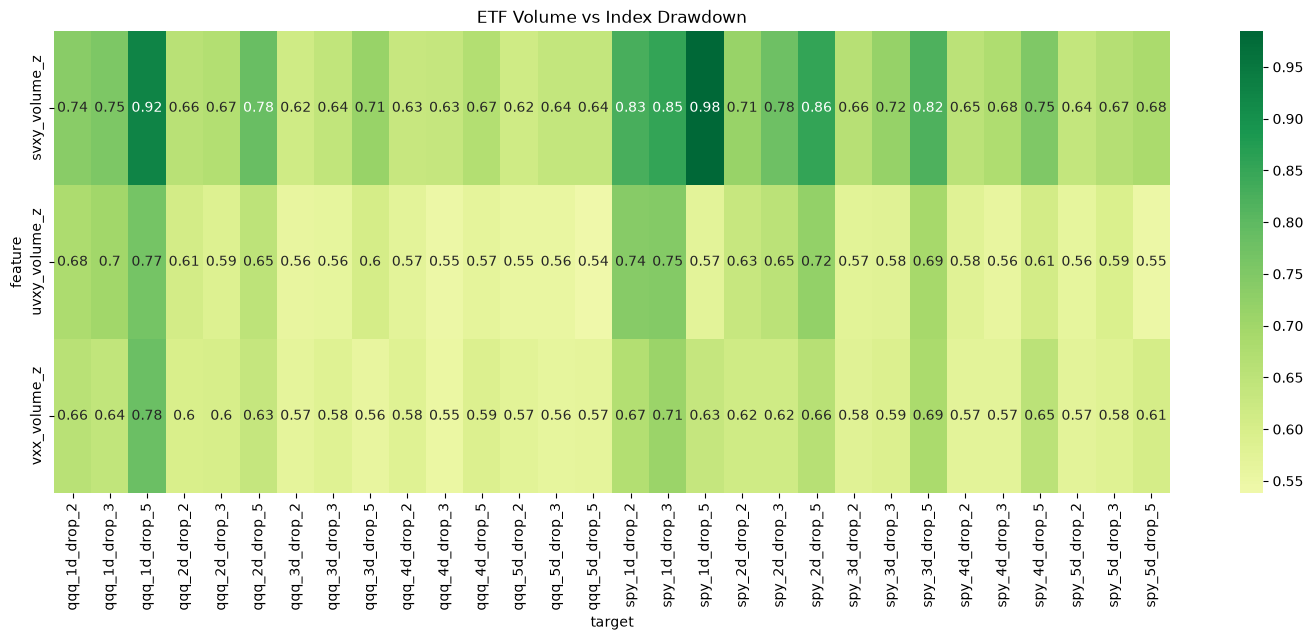

In [29]:
pivot_df = auc_df.pivot(
    index="feature",
    columns="target",
    values="roc_auc"
)
plt.figure(figsize=(18, 6))
sns.heatmap(
    pivot_df,
    annot=True,
    cmap="RdYlGn",
    center=0.5
)
plt.title("ETF Volume vs Index Drawdown")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"7_ROC_AUC_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()

#### 11. ETF出来高異常時の指数急落イベントスタディ

##### 目的

ETF出来高異常発生時に

- QQQ急落
- SPY急落

の発生率が上昇するか確認する。

Later1アラート候補となる
ルールベース条件の有効性を評価する。

In [30]:
FLOW_FEATURES = ["uvxy_volume_z", "svxy_volume_z", "vxx_volume_z"]
EVENT_THRESHOLDS = [1, 2, 3, 4]
TARGETS = [
    "qqq_1d_drop_2",
    "qqq_1d_drop_3",
    "qqq_1d_drop_5",
    "spy_1d_drop_2",
    "spy_1d_drop_3",
    "spy_1d_drop_5"
]

#### 12. 通常時発生率

##### 目的

急落イベントのベースラインを確認する。

イベント発生率の増加倍率(Lift)算出に利用する。

In [31]:
# TARGETS内の各ターゲットについて、ベースライン統計量を算出する。
baseline_rows = []
# 各ターゲットのベースライン統計量を格納するリストを初期化する
for target in TARGETS:
    # 各ターゲットのベースライン統計量を計算する
    baseline_rows.append({
        "target": target,
        "base_rate": research_df[target].mean(),
        "event_count": research_df[target].sum()
    })
baseline_df = pd.DataFrame(baseline_rows)
display(baseline_df)

,target,base_rate,event_count
0,qqq_1d_drop_2,0.053628,238
1,qqq_1d_drop_3,0.019603,87
2,qqq_1d_drop_5,0.002929,13
3,spy_1d_drop_2,0.029518,131
4,spy_1d_drop_3,0.009013,40
5,spy_1d_drop_5,0.000901,4


#### 13. ETF出来高イベントスタディ

##### 目的

出来高閾値を超えた場合の

- 発生件数
- 急落発生率
- Lift

を確認する。

In [32]:
# 各フロー特徴量と閾値に対して、ターゲットのイベント率とリフトを計算する
event_rows = []
# 各フロー特徴量と閾値の組み合わせごとにサンプルを抽出し、ターゲットのイベント率とリフトを計算する
for feature in FLOW_FEATURES:
    # 各フロー特徴量に対して処理を行う
    for threshold in EVENT_THRESHOLDS:
        # 各閾値に対して処理を行う
        sample_df = research_df[research_df[feature] >= threshold]
        # サンプル数を取得する
        n_samples = len(sample_df)
        # 各ターゲットに対してイベント率とリフトを計算する
        for target in TARGETS:
            # 各ターゲットに対してイベント率とリフトを計算する
            event_rate = (sample_df[target].mean())
            # ベースラインイベント率を取得する
            baseline_rate = (research_df[target].mean())
            lift = np.nan
            # リフトを計算する前にベースラインイベント率が0でないことを確認する
            if baseline_rate > 0: lift = (event_rate / baseline_rate)
            # 計算結果を辞書にまとめてリストに追加する
            event_rows.append({
                "feature": feature,
                "threshold": threshold,
                "target": target,
                "samples": n_samples,
                "event_rate": event_rate,
                "baseline_rate": baseline_rate,
                "lift": lift
            })
event_study_df = pd.DataFrame(event_rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"13_event_study_df_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = event_study_df.copy()
df.to_csv(output_path)
display(event_study_df)

,feature,threshold,target,samples,event_rate,baseline_rate,lift
0,uvxy_volume_z,1,qqq_1d_drop_2,759,0.117260,0.053628,2.186546
1,uvxy_volume_z,1,qqq_1d_drop_3,759,0.048748,0.019603,2.486726
2,uvxy_volume_z,1,qqq_1d_drop_5,759,0.009223,0.002929,3.148475
3,uvxy_volume_z,1,spy_1d_drop_2,759,0.064559,0.029518,2.187108
4,uvxy_volume_z,1,spy_1d_drop_3,759,0.022398,0.009013,2.485046
...,...,...,...,...,...,...,...
67,vxx_volume_z,4,qqq_1d_drop_3,36,0.166667,0.019603,8.501916
68,vxx_volume_z,4,qqq_1d_drop_5,36,0.055556,0.002929,18.965812
69,vxx_volume_z,4,spy_1d_drop_2,36,0.194444,0.029518,6.587362
70,vxx_volume_z,4,spy_1d_drop_3,36,0.111111,0.009013,12.327778


#### 14. 高Liftシグナル抽出

##### 目的

Later1候補となる
有効なシグナルを抽出する。

In [33]:
# サンプル数が20以上のイベントを抽出し、リフトの降順でソートして上位50件を表示する
candidate_df = (
    event_study_df.query("samples >= 20")
    .sort_values( "lift", ascending=False)
)
display(candidate_df.head(50))

,feature,threshold,target,samples,event_rate,baseline_rate,lift
71,vxx_volume_z,4,spy_1d_drop_5,36,0.027778,0.000901,30.819444
41,svxy_volume_z,3,spy_1d_drop_5,114,0.026316,0.000901,29.197368
47,svxy_volume_z,4,spy_1d_drop_5,38,0.026316,0.000901,29.197368
44,svxy_volume_z,4,qqq_1d_drop_5,38,0.078947,0.002929,26.951417
38,svxy_volume_z,3,qqq_1d_drop_5,114,0.061404,0.002929,20.962213
46,svxy_volume_z,4,spy_1d_drop_3,38,0.184211,0.009013,20.438158
68,vxx_volume_z,4,qqq_1d_drop_5,36,0.055556,0.002929,18.965812
65,vxx_volume_z,3,spy_1d_drop_5,82,0.012195,0.000901,13.530488
20,uvxy_volume_z,4,qqq_1d_drop_5,51,0.039216,0.002929,13.387632
35,svxy_volume_z,2,spy_1d_drop_5,256,0.011719,0.000901,13.001953


#### 15. QQQ翌日-2%急落分析

##### 目的

Later1候補として最も重要な

QQQ翌日-2%

の発生率を比較する。

In [34]:
qqq_drop_df = (
    event_study_df[event_study_df["target"] == "qqq_1d_drop_2"]
    .sort_values(["feature", "threshold"])
)
display(qqq_drop_df)

,feature,threshold,target,samples,event_rate,baseline_rate,lift
24,svxy_volume_z,1,qqq_1d_drop_2,558,0.143369,0.053628,2.673413
30,svxy_volume_z,2,qqq_1d_drop_2,256,0.175781,0.053628,3.277803
36,svxy_volume_z,3,qqq_1d_drop_2,114,0.245614,0.053628,4.579979
42,svxy_volume_z,4,qqq_1d_drop_2,38,0.342105,0.053628,6.379257
0,uvxy_volume_z,1,qqq_1d_drop_2,759,0.117260,0.053628,2.186546
6,uvxy_volume_z,2,qqq_1d_drop_2,285,0.182456,0.053628,3.402270
12,uvxy_volume_z,3,qqq_1d_drop_2,121,0.190083,0.053628,3.544482
18,uvxy_volume_z,4,qqq_1d_drop_2,51,0.235294,0.053628,4.387543
48,vxx_volume_z,1,qqq_1d_drop_2,389,0.156812,0.053628,2.924089
54,vxx_volume_z,2,qqq_1d_drop_2,188,0.191489,0.053628,3.570713


#### 16. QQQ翌日-2% Lift可視化

##### 目的

閾値上昇と急落確率上昇の関係を確認する。

saved: /workspace/data/figures/16_QQQ_Next_Day_-2%_Drawdown_Lift_2010-01-01_2026-10-24.png


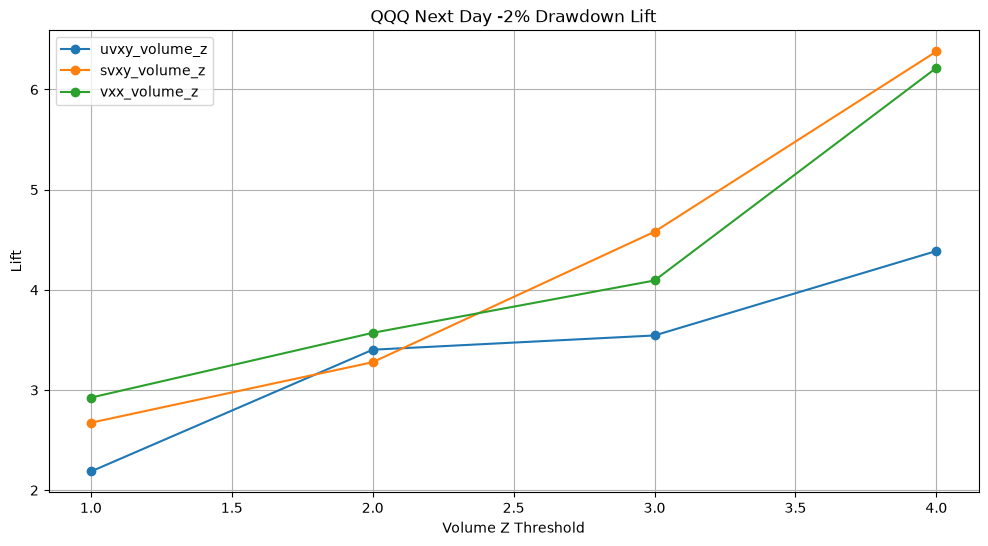

In [35]:
plt.figure(figsize=(12, 6))
# QQQの翌日-2%ドローダウン発生時における、各種フロー特性別の推移をプロットする。
for feature in FLOW_FEATURES:
    # 各フロー特性ごとにデータを抽出する
    plot_df = qqq_drop_df[qqq_drop_df["feature"] == feature]
    # プロット用のデータフレームを作成する
    plt.plot(
        plot_df["threshold"],
        plot_df["lift"],
        marker="o",
        label=feature
    )
plt.title("QQQ Next Day -2% Drawdown Lift")
plt.xlabel("Volume Z Threshold")
plt.ylabel("Lift")
plt.grid()
plt.legend()
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"16_QQQ_Next_Day_-2%_Drawdown_Lift_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()

#### 17. Later1ルール候補

##### 目的

実運用可能な警戒レベル候補を抽出する。

In [36]:
# QQQの翌日-2%ドローダウン発生時における、各種フロー特性の候補を抽出する
later1_candidate_df = (
    event_study_df.query("target == 'qqq_1d_drop_2' and samples >= 20")
    .sort_values(
        "lift",
        ascending=False
    )
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"17_later1_candidate_df_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = later1_candidate_df.copy()
df.to_csv(output_path)
display(later1_candidate_df)

,feature,threshold,target,samples,event_rate,baseline_rate,lift
42,svxy_volume_z,4,qqq_1d_drop_2,38,0.342105,0.053628,6.379257
66,vxx_volume_z,4,qqq_1d_drop_2,36,0.333333,0.053628,6.215686
36,svxy_volume_z,3,qqq_1d_drop_2,114,0.245614,0.053628,4.579979
18,uvxy_volume_z,4,qqq_1d_drop_2,51,0.235294,0.053628,4.387543
60,vxx_volume_z,3,qqq_1d_drop_2,82,0.219512,0.053628,4.093257
54,vxx_volume_z,2,qqq_1d_drop_2,188,0.191489,0.053628,3.570713
12,uvxy_volume_z,3,qqq_1d_drop_2,121,0.190083,0.053628,3.544482
6,uvxy_volume_z,2,qqq_1d_drop_2,285,0.182456,0.053628,3.402270
30,svxy_volume_z,2,qqq_1d_drop_2,256,0.175781,0.053628,3.277803
48,vxx_volume_z,1,qqq_1d_drop_2,389,0.156812,0.053628,2.924089


#### 18. コンセンサスシグナル分析

##### 目的

複数ETFで同時に出来高異常が発生した場合に
QQQ翌日急落確率が上昇するか確認する。

Later1アラート候補となる
複合シグナルの有効性を評価する。

In [37]:
TARGET = "qqq_1d_drop_2"
CONSENSUS_THRESHOLDS = [2, 3, 4]

#### 19. 2ETF同時シグナル

##### 目的

2銘柄同時異常出来高の
急落発生率とLiftを評価する。

In [38]:
# ペアルールに基づくイベント発生率の解析
pair_rules = [
    ("uvxy_volume_z", "svxy_volume_z"),
    ("uvxy_volume_z", "vxx_volume_z"),
    ("svxy_volume_z", "vxx_volume_z")
]
# 各ペアルールと閾値に対して、イベント発生率を計算する
rows = []
baseline_rate = (research_df[TARGET].mean())
# 各ペアルールと閾値に対して、サンプルを抽出し、イベント発生率を計算する
for threshold in CONSENSUS_THRESHOLDS:
    # 各ペアルールに対してサンプルを抽出し、イベント発生率を計算する
    for f1, f2 in pair_rules:
        # サンプルを抽出する条件を表示
        sample_df = research_df[
            (research_df[f1] >= threshold)
            &
            (research_df[f2] >= threshold)
        ]
        # サンプルが存在しない場合はスキップする
        if len(sample_df) == 0:
            continue
        # イベント発生率を計算する
        event_rate = (sample_df[TARGET].mean())
        # 計算結果を辞書に追加する
        rows.append({
            "rule": f"{f1} & {f2}",
            "threshold": threshold,
            "samples": len(sample_df),
            "event_rate": event_rate,
            "baseline": baseline_rate,
            "lift": event_rate / baseline_rate
        })
# ペアルールごとのイベント発生率をまとめたデータフレームを作成する
pair_df = pd.DataFrame(rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"19_2ETF_pair_df_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = pair_df.copy()
df.to_csv(output_path)
# イベント発生率の高い順に表示する
display(pair_df.sort_values("lift", ascending=False))

,rule,threshold,samples,event_rate,baseline,lift
8,svxy_volume_z & vxx_volume_z,4,14,0.571429,0.053628,10.655462
5,svxy_volume_z & vxx_volume_z,3,28,0.464286,0.053628,8.657563
7,uvxy_volume_z & vxx_volume_z,4,16,0.437500,0.053628,8.158088
6,uvxy_volume_z & svxy_volume_z,4,19,0.368421,0.053628,6.869969
2,svxy_volume_z & vxx_volume_z,2,80,0.312500,0.053628,5.827206
3,uvxy_volume_z & svxy_volume_z,3,46,0.282609,0.053628,5.269821
1,uvxy_volume_z & vxx_volume_z,2,102,0.274510,0.053628,5.118800
4,uvxy_volume_z & vxx_volume_z,3,44,0.272727,0.053628,5.085561
0,uvxy_volume_z & svxy_volume_z,2,129,0.240310,0.053628,4.481076


#### 20. 3ETF同時シグナル

##### 目的

全ETFが同時に異常出来高となった場合の
急落確率を確認する。

In [39]:
# 3つのボラティリティ指数の出来高に基づくイベント発生率の解析結果を表示する
rows = []
# 各閾値に対して、3つのボラティリティ指数の出来高がすべて閾値以上であるサンプルを抽出し、イベント発生率を計算する
for threshold in CONSENSUS_THRESHOLDS:
    sample_df = research_df[
        (research_df["uvxy_volume_z"] >= threshold)
        &
        (research_df["svxy_volume_z"] >= threshold)
        &
        (research_df["vxx_volume_z"] >= threshold)
    ]
    # サンプルが存在する場合にイベント発生率を計算する
    if len(sample_df) == 0:
        continue
    # ベースラインのイベント発生率を取得
    event_rate = (
        sample_df[TARGET]
        .mean()
    )
    # 計算結果を辞書に追加する
    rows.append({
        "rule": "uvxy_volume_z & svxy_volume_z & vxx_volume_z",
        "threshold": threshold,
        "samples": len(sample_df),
        "event_rate": event_rate,
        "baseline": baseline_rate,
        "lift": event_rate / baseline_rate
    })
# データフレームに変換
triple_df = pd.DataFrame(rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"20_3ETF_triple_df_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = triple_df.copy()
df.to_csv(output_path)
display(triple_df)

,rule,threshold,samples,event_rate,baseline,lift
0,uvxy_volume_z & svxy_volume_z & vxx_volume_z,2,62,0.370968,0.053628,6.917457
1,uvxy_volume_z & svxy_volume_z & vxx_volume_z,3,22,0.409091,0.053628,7.628342
2,uvxy_volume_z & svxy_volume_z & vxx_volume_z,4,10,0.500000,0.053628,9.323529


#### 21. シグナルスコア方式

##### 目的

Later1候補として
複数ETFの異常出来高数を集計する。

In [40]:
# ボリュームシグナルスコアを計算してデータフレームに追加する
for threshold in [2, 3, 4]:
    # 各閾値に対してボリュームシグナルスコアを計算する
    research_df[f"volume_signal_score_{threshold}"] = (
        (research_df["uvxy_volume_z"] >= threshold).astype(int)
        +
        (research_df["svxy_volume_z"] >= threshold).astype(int)
        +
        (research_df["vxx_volume_z"] >= threshold).astype(int)
    )

#### 22. シグナルスコア別急落発生率

##### 目的

異常出来高ETF数と
QQQ急落確率の関係を確認する。


In [41]:
# ボリュームシグナルスコアに基づくイベント発生率の解析結果を表示する
score_rows = []
# 各閾値に対して、ボリュームシグナルスコアごとのサンプルを抽出し、イベント発生率を計算する
for threshold in [2, 3, 4]:
    # ボリュームシグナルスコアの列名を作成する
    score_col = (f"volume_signal_score_{threshold}")
    # 各スコアに対してサンプルを抽出し、イベント発生率を計算する
    for score in sorted(research_df[score_col].dropna().unique()):
        # サンプルを抽出する条件を表示
        sample_df = research_df[research_df[score_col] == score]
        # サンプル数が0の場合はスキップ
        score_rows.append({
            "threshold": threshold,
            "score": score,
            "samples": len(sample_df),
            "event_rate":sample_df[TARGET].mean(),
            "lift":(sample_df[TARGET].mean() / baseline_rate)
        })
# データフレームに変換して表示する
score_df = pd.DataFrame(score_rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"22_volume_signal_score__{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = score_df.copy()
df.to_csv(output_path)
display(score_df)

,threshold,score,samples,event_rate,lift
0,2,0,3958,0.041940,0.782065
1,2,1,293,0.116041,2.163823
2,2,2,125,0.120000,2.237647
3,2,3,62,0.370968,6.917457
4,3,0,4217,0.046953,0.875532
5,3,1,147,0.136054,2.537015
6,3,2,52,0.211538,3.944570
7,3,3,22,0.409091,7.628342
8,4,0,4352,0.050092,0.934067
9,4,1,57,0.140351,2.617131


#### 23. Later1候補ランキング

##### 目的

実運用候補となる
複合シグナルを抽出する。

In [42]:
# ペアおよびトリプルの候補を結合し、サンプル数が20以上のものを抽出してリフト順にソートする
later1_candidates = pd.concat([pair_df, triple_df], ignore_index=True)
# サンプル数が20以上の候補を抽出してリフト順にソートする
later1_candidates = (
    later1_candidates.query("samples >= 20")
    .sort_values("lift", ascending=False)
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"23_later1_candidates_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = later1_candidates.copy()
df.to_csv(output_path)
display(later1_candidates)

,rule,threshold,samples,event_rate,baseline,lift
5,svxy_volume_z & vxx_volume_z,3,28,0.464286,0.053628,8.657563
10,uvxy_volume_z & svxy_volume_z & vxx_volume_z,3,22,0.409091,0.053628,7.628342
9,uvxy_volume_z & svxy_volume_z & vxx_volume_z,2,62,0.370968,0.053628,6.917457
2,svxy_volume_z & vxx_volume_z,2,80,0.312500,0.053628,5.827206
3,uvxy_volume_z & svxy_volume_z,3,46,0.282609,0.053628,5.269821
1,uvxy_volume_z & vxx_volume_z,2,102,0.274510,0.053628,5.118800
4,uvxy_volume_z & vxx_volume_z,3,44,0.272727,0.053628,5.085561
0,uvxy_volume_z & svxy_volume_z,2,129,0.240310,0.053628,4.481076


#### 24. Later1設計用メモ

##### 目的

実運用で採用すべき
閾値候補を整理する。

In [43]:
print(
    "Baseline :",
    baseline_rate
)
display(
    later1_candidates.head(20)
)

Baseline : 0.05362776025236593


,rule,threshold,samples,event_rate,baseline,lift
5,svxy_volume_z & vxx_volume_z,3,28,0.464286,0.053628,8.657563
10,uvxy_volume_z & svxy_volume_z & vxx_volume_z,3,22,0.409091,0.053628,7.628342
9,uvxy_volume_z & svxy_volume_z & vxx_volume_z,2,62,0.370968,0.053628,6.917457
2,svxy_volume_z & vxx_volume_z,2,80,0.312500,0.053628,5.827206
3,uvxy_volume_z & svxy_volume_z,3,46,0.282609,0.053628,5.269821
1,uvxy_volume_z & vxx_volume_z,2,102,0.274510,0.053628,5.118800
4,uvxy_volume_z & vxx_volume_z,3,44,0.272727,0.053628,5.085561
0,uvxy_volume_z & svxy_volume_z,2,129,0.240310,0.053628,4.481076


#### 25. Later1 リスクレベル検証

##### 目的

コンセンサスシグナルが

- QQQ翌日 -2%
- QQQ翌日 -3%
- QQQ翌日 -5%

のどこまで説明できるか確認する。

Later1のリスクレベル設計に利用する。

In [44]:
TARGETS = ["qqq_1d_drop_2", "qqq_1d_drop_3", "qqq_1d_drop_5"]

#### 26. SVXY + VXX コンセンサス検証

##### 目的

最も有力なシグナル

SVXY_Z >= N
AND
VXX_Z >= N

の急落発生率を測定する。

In [45]:
# SVXYとVXXの出来高に基づくイベント発生率の解析結果を表示する
rows = []
# 各閾値に対して、SVXYとVXXの出来高がすべて閾値以上であるサンプルを抽出し、イベント発生率を計算する
for threshold in [2, 3, 4]:
    # 閾値以上のサンプルを抽出する
    sample_df = research_df[
        (research_df["svxy_volume_z"] >= threshold)
        &
        (research_df["vxx_volume_z"] >= threshold)
    ]
    # サンプルが存在する場合にイベント発生率を計算する
    for target in TARGETS:
        # ベースラインのイベント発生率を取得
        baseline_rate = (research_df[target].mean())
        event_rate = (sample_df[target].mean())
        lift = np.nan
        # ベースラインが0より大きい場合にリフトを計算
        if baseline_rate > 0:
            lift = (event_rate / baseline_rate)
        # 結果を行に追加
        rows.append({
            "rule": "SVXY & VXX",
            "threshold": threshold,
            "target": target,
            "samples": len(sample_df),
            "event_rate": event_rate,
            "baseline": baseline_rate,
            "lift": lift
        })
# データフレームを作成して表示する
svxy_vxx_df = pd.DataFrame(rows)
display(svxy_vxx_df)

,rule,threshold,target,samples,event_rate,baseline,lift
0,SVXY & VXX,2,qqq_1d_drop_2,80,0.312500,0.053628,5.827206
1,SVXY & VXX,2,qqq_1d_drop_3,80,0.175000,0.019603,8.927011
2,SVXY & VXX,2,qqq_1d_drop_5,80,0.075000,0.002929,25.603846
3,SVXY & VXX,3,qqq_1d_drop_2,28,0.464286,0.053628,8.657563
4,SVXY & VXX,3,qqq_1d_drop_3,28,0.250000,0.019603,12.752874
5,SVXY & VXX,3,qqq_1d_drop_5,28,0.071429,0.002929,24.384615
6,SVXY & VXX,4,qqq_1d_drop_2,14,0.571429,0.053628,10.655462
7,SVXY & VXX,4,qqq_1d_drop_3,14,0.214286,0.019603,10.931034
8,SVXY & VXX,4,qqq_1d_drop_5,14,0.142857,0.002929,48.769231


#### 27. 3ETFコンセンサス検証

##### 目的

UVXY・SVXY・VXXの
同時異常出来高シグナルを評価する。


In [46]:
# 
rows = []
# 
for threshold in [2, 3, 4]:
    # 
    sample_df = research_df[
        (research_df["uvxy_volume_z"] >= threshold)
        &
        (research_df["svxy_volume_z"] >= threshold)
        &
        (research_df["vxx_volume_z"] >= threshold)
    ]
    # 
    for target in TARGETS:
        baseline_rate = (research_df[target].mean())
        event_rate = (sample_df[target].mean())
        lift = np.nan
        # 
        if baseline_rate > 0: lift = (event_rate / baseline_rate)
        # 
        rows.append({
            "rule": "UVXY & SVXY & VXX",
            "threshold": threshold,
            "target": target,
            "samples": len(sample_df),
            "event_rate": event_rate,
            "baseline": baseline_rate,
            "lift": lift
        })
# 
triple_risk_df = pd.DataFrame(rows)
display(triple_risk_df)

,rule,threshold,target,samples,event_rate,baseline,lift
0,UVXY & SVXY & VXX,2,qqq_1d_drop_2,62,0.370968,0.053628,6.917457
1,UVXY & SVXY & VXX,2,qqq_1d_drop_3,62,0.193548,0.019603,9.873192
2,UVXY & SVXY & VXX,2,qqq_1d_drop_5,62,0.064516,0.002929,22.024814
3,UVXY & SVXY & VXX,3,qqq_1d_drop_2,22,0.409091,0.053628,7.628342
4,UVXY & SVXY & VXX,3,qqq_1d_drop_3,22,0.181818,0.019603,9.274817
5,UVXY & SVXY & VXX,3,qqq_1d_drop_5,22,0.045455,0.002929,15.517483
6,UVXY & SVXY & VXX,4,qqq_1d_drop_2,10,0.500000,0.053628,9.323529
7,UVXY & SVXY & VXX,4,qqq_1d_drop_3,10,0.100000,0.019603,5.101149
8,UVXY & SVXY & VXX,4,qqq_1d_drop_5,10,0.100000,0.002929,34.138462


#### 28. リスクレベル候補比較

##### 目的

Later1で採用する
リスクレベル候補を抽出する。

In [47]:
# 
risk_compare_df = pd.concat([svxy_vxx_df, triple_risk_df], ignore_index=True)

display(
    risk_compare_df.sort_values(["target", "lift"],
        ascending=[True, False]
    )
)

,rule,threshold,target,samples,event_rate,baseline,lift
6,SVXY & VXX,4,qqq_1d_drop_2,14,0.571429,0.053628,10.655462
15,UVXY & SVXY & VXX,4,qqq_1d_drop_2,10,0.500000,0.053628,9.323529
3,SVXY & VXX,3,qqq_1d_drop_2,28,0.464286,0.053628,8.657563
12,UVXY & SVXY & VXX,3,qqq_1d_drop_2,22,0.409091,0.053628,7.628342
9,UVXY & SVXY & VXX,2,qqq_1d_drop_2,62,0.370968,0.053628,6.917457
0,SVXY & VXX,2,qqq_1d_drop_2,80,0.312500,0.053628,5.827206
4,SVXY & VXX,3,qqq_1d_drop_3,28,0.250000,0.019603,12.752874
7,SVXY & VXX,4,qqq_1d_drop_3,14,0.214286,0.019603,10.931034
10,UVXY & SVXY & VXX,2,qqq_1d_drop_3,62,0.193548,0.019603,9.873192
13,UVXY & SVXY & VXX,3,qqq_1d_drop_3,22,0.181818,0.019603,9.274817


#### 29. QQQ急落深度別 Lift 可視化

##### 目的

急落の深さと
シグナル強度の関係を可視化する。

saved: /workspace/data/figures/29_QQQ_Drawdown_Lift_2010-01-01_2026-10-24.png


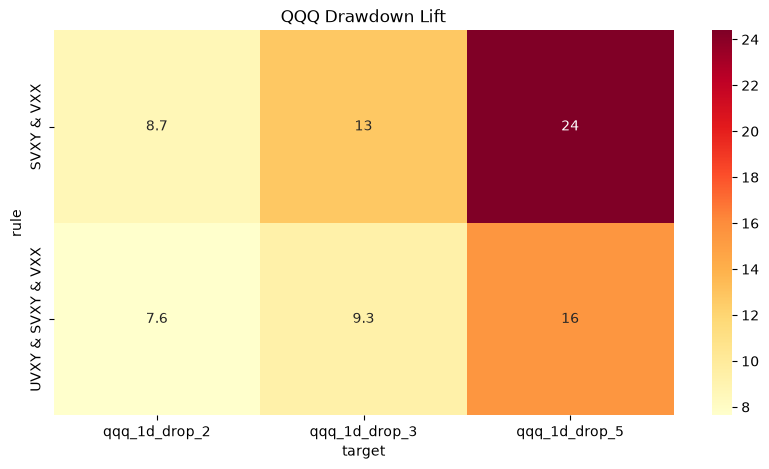

In [48]:
# 
plot_df = risk_compare_df[risk_compare_df["threshold"] == 3]
# 
pivot_df = plot_df.pivot(index="rule", columns="target", values="lift")
# 
plt.figure(figsize=(10, 5))
sns.heatmap(
    pivot_df,
    annot=True,
    cmap="YlOrRd"
)
plt.title("QQQ Drawdown Lift")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"29_QQQ_Drawdown_Lift_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()


#### 30. Later1 リスクレベル候補

##### 目的

運用可能な
リスクレベル条件を抽出する。

In [49]:
# サンプルとリフトに基づいて、risk_compare_df を later1_risk_level_df 用にフィルタリングおよびソート
later1_risk_level_df = (
    risk_compare_df
    .query("samples >= 20")
    .sort_values("lift", ascending=False)
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"30_later1_risk_level_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = later1_risk_level_df.copy()
df.to_csv(output_path)
# フィルタリングおよびソート後のデータフレームを表示
display(later1_risk_level_df)

,rule,threshold,target,samples,event_rate,baseline,lift
2,SVXY & VXX,2,qqq_1d_drop_5,80,0.075000,0.002929,25.603846
5,SVXY & VXX,3,qqq_1d_drop_5,28,0.071429,0.002929,24.384615
11,UVXY & SVXY & VXX,2,qqq_1d_drop_5,62,0.064516,0.002929,22.024814
14,UVXY & SVXY & VXX,3,qqq_1d_drop_5,22,0.045455,0.002929,15.517483
4,SVXY & VXX,3,qqq_1d_drop_3,28,0.250000,0.019603,12.752874
10,UVXY & SVXY & VXX,2,qqq_1d_drop_3,62,0.193548,0.019603,9.873192
13,UVXY & SVXY & VXX,3,qqq_1d_drop_3,22,0.181818,0.019603,9.274817
1,SVXY & VXX,2,qqq_1d_drop_3,80,0.175000,0.019603,8.927011
3,SVXY & VXX,3,qqq_1d_drop_2,28,0.464286,0.053628,8.657563
12,UVXY & SVXY & VXX,3,qqq_1d_drop_2,22,0.409091,0.053628,7.628342


# VIX関連ETF出来高と市場ストレスの検証レポート

## 検証目的

VIX関連ETF（UVXY・SVXY・VXX）の出来高異常が、市場ストレスや株価指数急落の先行シグナルとして機能するかを検証した。

---

## VIX予測に関する結果

出来高Zスコアは将来VIXリターンに対して短期的な説明力を持つことが確認された。

特に、

- UVXY出来高
- SVXY出来高
- VXX出来高

は1〜5営業日以内のVIX急騰イベントに対して有意な予測力を持った。

一方で10営業日以降の説明力は急速に低下した。

---

## 対数変換の評価

出来高を対数変換すると説明力は低下した。

これは出来高スパイクそのものがシグナルであり、極端値の圧縮によって重要な情報が失われるためと考えられる。

---

## Nasdaq100急落との関係

VIX急騰よりも、QQQ急落イベントに対する説明力の方が実用的であった。

単独シグナルではSVXY出来高が最も高い識別能力を示した。

解釈としては、

- VXX出来高増加 = ヘッジ需要の増加
- SVXY出来高増加 = リスクテイク戦略の解消

を表している可能性がある。

特にSVXY出来高は、市場参加者がボラティリティ上昇を織り込み始めた初期段階を捉えている可能性がある。

---

## コンセンサスシグナル分析

最も有効だったルールは

SVXY_Z >= 3
AND
VXX_Z >= 3

であった。

QQQ翌日-2%の発生率は

- 通常時: 5.36%
- シグナル発生時: 46.4%

となり、

Lift = 8.66

を記録した。

---

## 暴落イベントとの関係

QQQ翌日-5%という稀な急落イベントについても強いシグナルが確認された。

SVXY_Z >= 2
AND
VXX_Z >= 2

の条件では

- 通常時発生率: 0.29%
- シグナル発生時発生率: 7.5%

となり、

Lift = 25.6

を記録した。

これは通常時と比較して約25倍高い発生率である。

---

## 現時点の結論

本研究から、

VIX関連ETF出来高は単なるVIX先行指標ではなく、

「機関投資家やヘッジファンドのリスクオフ行動を観測する市場ストレスセンサー」

として機能している可能性が高いことが示唆された。

特に

- SVXY出来高異常
- VXX出来高異常
- SVXY + VXXの同時異常

は、Nasdaq100急落の有力な先行警戒シグナル候補である。

この結果を踏まえ、次フェーズでは Later1Alert クラスを設計し、ETF出来高に基づくリスクレベル判定ロジックを実装する。